In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.metrics import mean_absolute_error

In [39]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [40]:
# Fix random state
random_state = 42

In [41]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 108526 stars
galah contains 116050 stars
gr8 contains 1436 stars


In [42]:
apogee = apogee[apogee.parallax >2]
print (len(apogee))
galah = galah[galah.parallax > 3]
print (len(galah))


23511
19678


# Here we focus on getting Fe from no abundance

In [43]:
columns_for_Fe = ['radial_velocity', 'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', # 'parallax',  #'pmra', 'pmdec', #'ra', 'dec',
                'fe_h', ]

apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

In [44]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['Log_W_lsr'] = np.log(X['W_lsr'] + np.abs(X['W_lsr'].min()) + epsilon)
    X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)
galah = fit_trasform(galah)
gr8 = fit_trasform(gr8)

### Identifying and exluding null values

In [45]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [46]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [47]:
#gr8.isnull().sum() # No null values

In [48]:
#harps.isnull().sum() # No null values

### Spliting data into Trianing and Testing sets

In [49]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train, X_gr8], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train, y_gr8], ignore_index=True)


In [50]:
from scikeras.wrappers import KerasRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
from tensorflow.keras import Input

def build_keras_regressor(input_dim, lr=0.001):
    model = Sequential([
        Input(shape=(input_dim,)), 
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(16, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mae', metrics=['mae'])
    return model



dl_model = KerasRegressor(
    model=build_keras_regressor,
    model__lr=0.007,
    epochs=20,
    batch_size=64,
    verbose=0,
    #callbacks=[tf.keras.callbacks.EarlyStopping(monitor='mae', patience=5, restore_best_weights=True)]
    validation_split=0.2,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)


In [51]:
rfr = RandomForestRegressor(random_state=random_state, n_jobs=-1)
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lr = LinearRegression()  # no internal parallel
svr = SVR()  # no internal parallel
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)
catr = CatBoostRegressor(random_state=random_state, verbose=False, thread_count=-1)
extr = ExtraTreesRegressor(random_state=random_state, n_jobs=-1)


voting_r = VotingRegressor(estimators=[
    ('xgbr', xgbr),
    #('rfr', rfr),
    ('extr', extr),
    ('lgbr', lgbr),
    ('catr', catr)
])

model_names = {
    'dl_model': dl_model,
    'xgbr': xgbr,
    #'rfr': rfr,
    'extr': extr,  
    #'svr': svr,
    #'lr': lr,
    'lgbr': lgbr,
    'catr': catr,
    #'voting_r': voting_r 
}


In [52]:
def model_test_CV_models(X, y, models, k=5, random_state=random_state):
    """
    Perform k-fold cross-validation for multiple models and return mean MAE scores and elapsed time.

    Parameters:
        X (DataFrame): Feature matrix.
        y (Series): Target vector.
        models (dict): Dictionary of model_name: model_instance.
        k (int): Number of folds.
        random_state (int): Seed for reproducibility.

    Returns:
        dict: {model_name: {'mean_mae': ..., 'std_mae': ..., 'time_sec': ...}}
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # Special handling for scikeras models
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [53]:
baseline_results = model_test_CV_models(X_gr8, y_gr8, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: dl_model
dl_model done in 38.01s → MAE: 0.176 ± 0.008

Scoring model: xgbr
xgbr done in 1.24s → MAE: 0.191 ± 0.009

Scoring model: extr
extr done in 1.27s → MAE: 0.179 ± 0.009

Scoring model: lgbr
lgbr done in 1.61s → MAE: 0.185 ± 0.009

Scoring model: catr
catr done in 21.97s → MAE: 0.181 ± 0.007

dl_model | MAE: 0.176 ± 0.008
xgbr     | MAE: 0.191 ± 0.009
extr     | MAE: 0.179 ± 0.009
lgbr     | MAE: 0.185 ± 0.009
catr     | MAE: 0.181 ± 0.007


In [54]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))

        results[name] = {
            'mae_model': mae_model,
            'mae_baseline': mae_baseline
        }

        print(f"{name} | {test_name} MAE: {mae_model:.3f} (mean baseline: {mae_baseline:.3f})\n")

    return results


In [55]:
# Evaluate on Apogee test
results_apogee = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=apogee_test,
    target='fe_h',
    models=model_names,
    test_name='Apogee'
)

# Evaluate on HARPS test
results_harps = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=harps,
    target='fe_h',
    models=model_names,
    test_name='HARPS'
)

# Evaluate on GALAH test
results_galah = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=galah,
    target='fe_h',
    models=model_names,
    test_name='GALAH'
)

Training and evaluating dl_model on Apogee
dl_model | Apogee MAE: 0.136 (mean baseline: 0.145)

Training and evaluating xgbr on Apogee
xgbr | Apogee MAE: 0.137 (mean baseline: 0.145)

Training and evaluating extr on Apogee
extr | Apogee MAE: 0.142 (mean baseline: 0.145)

Training and evaluating lgbr on Apogee
lgbr | Apogee MAE: 0.135 (mean baseline: 0.145)

Training and evaluating catr on Apogee
catr | Apogee MAE: 0.135 (mean baseline: 0.145)

Training and evaluating dl_model on HARPS
dl_model | HARPS MAE: 0.179 (mean baseline: 0.204)

Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.178 (mean baseline: 0.204)

Training and evaluating extr on HARPS
extr | HARPS MAE: 0.173 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.173 (mean baseline: 0.204)

Training and evaluating catr on HARPS
catr | HARPS MAE: 0.176 (mean baseline: 0.204)

Training and evaluating dl_model on GALAH
dl_model | GALAH MAE: 0.139 (mean baseline: 0.148)

Training and evaluat

In [56]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


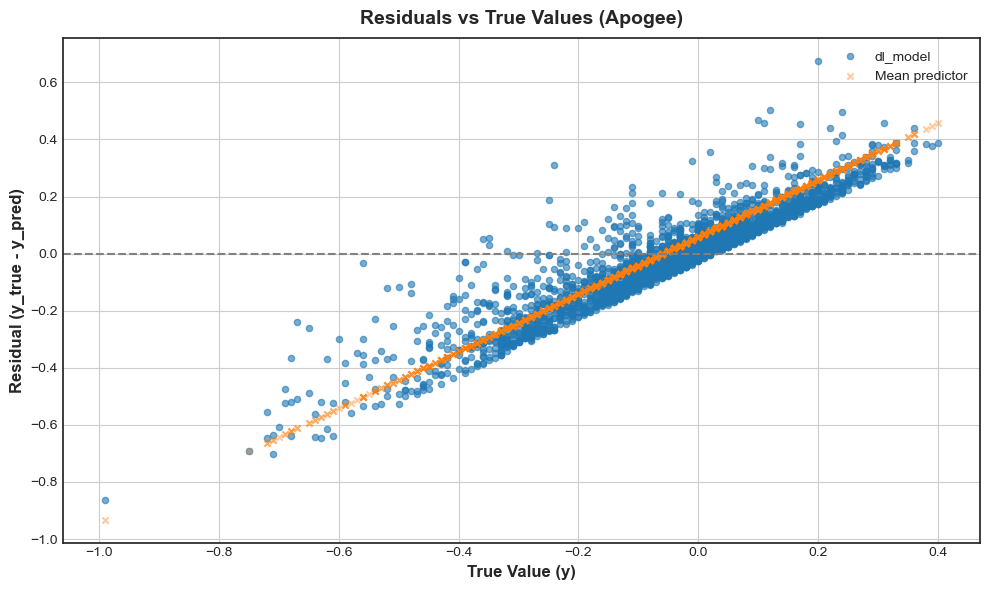

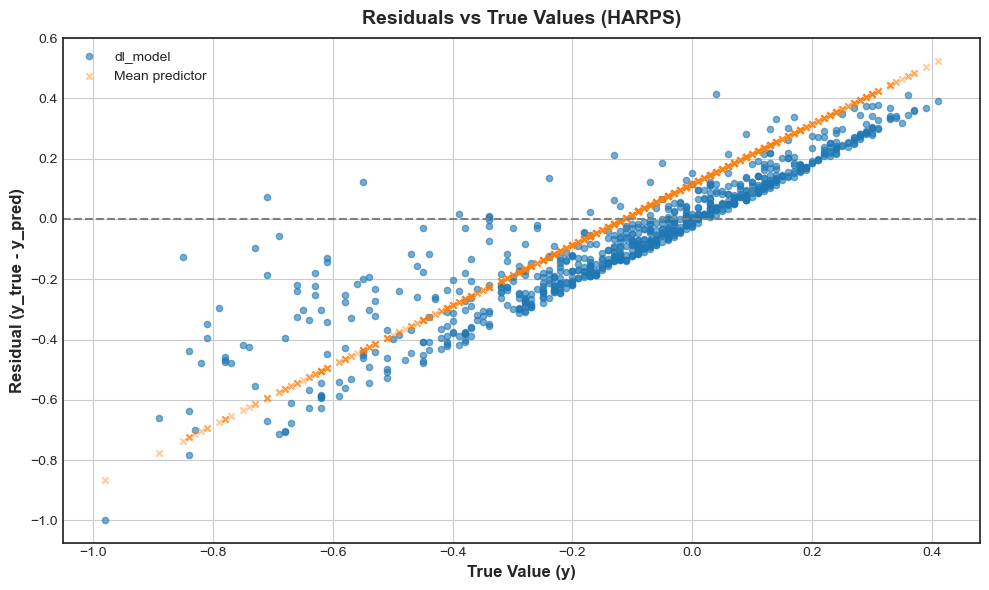

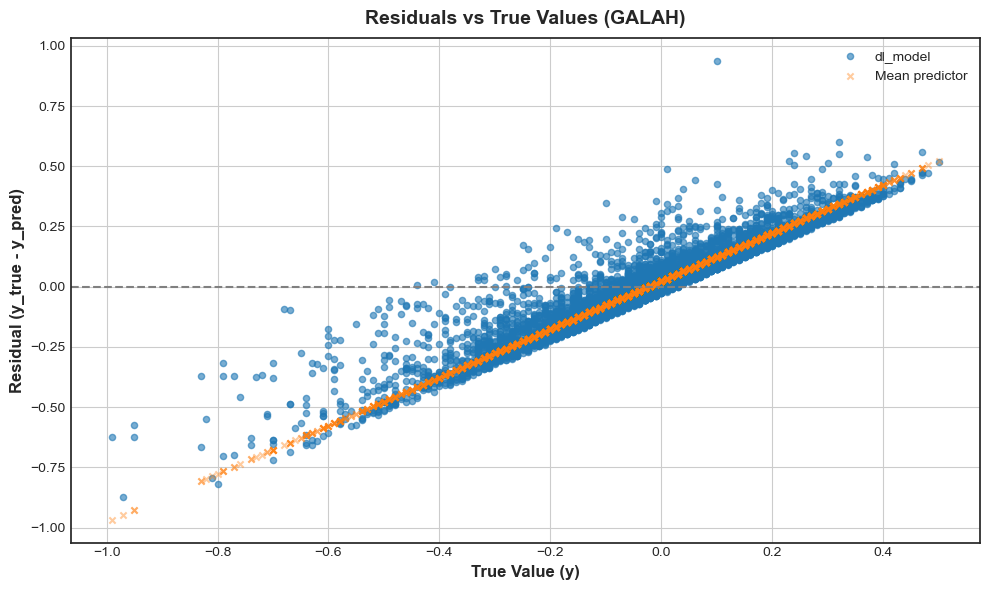

In [57]:
# Example for one model and one test set
best_model_name = 'dl_model'
model = model_names[best_model_name]
model.fit(X_combined_train, y_combined_train)

y_pred_apogee = model.predict(X_apogee_test)
plot_residuals_vs_true(y_apogee_test, y_pred_apogee, model_name=best_model_name, sample_name='Apogee')

y_pred_harps = model.predict(X_harps)
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')

y_pred_galah = model.predict(X_galah_test)
plot_residuals_vs_true(y_galah_test, y_pred_galah, model_name=best_model_name, sample_name='GALAH')
